# Ingeniería de características — exploración y selección

**Proyecto #2 · Notebook 1 de 4** · Maestría · 4T 2026 · Product Management · Clase Cloud
**Autor:** Danny García

---

Este notebook **decide** qué transformaciones se aplicarán a los datos y **por qué**. No
construye el pipeline —eso es el notebook 03—, sino que deja por escrito la lista de
operaciones que ese pipeline tendrá que ejecutar.

## Qué se predice

La competencia pide `item_cnt_month`: **las unidades que cada par tienda-producto venderá en
noviembre de 2015** (el mes 34). Esa columna no existe en los datos; se construye sumando
`item_cnt_day` dentro de cada mes.

## De dónde parte

Del EDA del Proyecto #1, que dejó cinco conclusiones que aquí se convierten en decisiones:

| Hallazgo del EDA | Consecuencia en este notebook |
|---|---|
| La rejilla mensual está vacía en un 85 % | Hay que **construir los ceros**, no solo las ventas |
| La PACF se corta en el rezago 1; la ACF decae hasta el 3 | Rezagos **1, 2 y 3** |
| Diciembre se repite los dos años completos | Rezago **12** y bandera de diciembre |
| El ciclo semanal es más fuerte que el anual | **Número de fines de semana** del mes |
| El 48 % de los pares de test no tiene historial | Agregados por **producto, tienda y categoría** |

## Índice

| # | Sección |
|---|---|
| 0 | [Configuración](#0) |
| 1 | [El conjunto de trabajo: la rejilla mensual](#1) |
| 2 | [Selección de los rezagos](#2) |
| 3 | [Los seis procesos de ingeniería de características](#3) |
| 4 | [La lista escrita del proceso](#4) |
| 5 | [Fuga de información: la regla que no se puede romper](#5) |

<a id="0"></a>
## 0. Configuración

In [1]:
# Librerias de uso general.
import time

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd

# Rutas del proyecto (definidas en el paquete, no escritas a mano aqui).
from predict_future_sales.config import FIGURES_DIR, RAW_DATA_DIR

# Operadores propios. Viven en el paquete y no en el notebook porque el
# pipeline se guardara en un .pkl, y un .pkl solo guarda DONDE esta el codigo,
# no el codigo en si.
from predict_future_sales.features import (
    CaracteristicasCalendario,
    LagFeatures,
    Mapper,
    OutlierCapper,
    UnirCatalogos,
    construir_rejilla,
    extraer_ciudad,
    extraer_tipo_categoria,
    panel_mensual,
)

print("pandas", pd.__version__)

2026-11-20 02:00:57.894 -06:00 | INFO     | predict_future_sales.config:<module>:11 - PROJ_ROOT path is: C:\Users\dgarc\OneDrive\Escritorio\Maestria\4T_2026\Product_Mang\Clase_Cloud\predict_future_sales


pandas 3.1.1


In [2]:
# Estilo de las graficas: la misma paleta del EDA, para que los dos proyectos
# se lean como uno solo.
AZUL, NARANJA, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
TINTA, TINTA2, REJILLA, EJE = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": EJE, "axes.labelcolor": TINTA2, "axes.titlecolor": TINTA,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 10, "axes.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8,
    "xtick.color": TINTA2, "ytick.color": TINTA2,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2, "figure.dpi": 110, "savefig.bbox": "tight",
    "font.family": "DejaVu Sans",
})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

def miles(x, _=None):
    """Formatea los ejes en miles y millones, para no leer ceros."""
    if abs(x) >= 1e6:
        return f"{x / 1e6:,.1f} M"
    if abs(x) >= 1e3:
        return f"{x / 1e3:,.0f} k"
    return f"{x:,.0f}"

FMT = FuncFormatter(miles)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
# Carga de los datos crudos. Son los mismos archivos del Proyecto #1.
sales = pd.read_csv(RAW_DATA_DIR / "sales_train.csv", encoding="utf-8")
items = pd.read_csv(RAW_DATA_DIR / "items.csv", encoding="utf-8")
cats = pd.read_csv(RAW_DATA_DIR / "item_categories.csv", encoding="utf-8")
shops = pd.read_csv(RAW_DATA_DIR / "shops.csv", encoding="utf-8")
test = pd.read_csv(RAW_DATA_DIR / "test.csv", encoding="utf-8")

print(f"ventas diarias : {len(sales):,} filas")
print(f"test (mes 34)  : {len(test):,} pares tienda-producto")

ventas diarias : 2,935,849 filas
test (mes 34)  : 214,200 pares tienda-producto


<a id="1"></a>
## 1. El conjunto de trabajo: la rejilla mensual

### Por qué no se puede entrenar con los datos tal como vienen

`sales_train.csv` solo contiene filas donde **hubo** una venta. Si se entrena con eso, el modelo
nunca ve un cero y aprende, implícitamente, que todo producto se vende en toda tienda todos los
meses.

El problema es que `test.csv` **sí** contiene los ceros: es la rejilla completa de 42 tiendas ×
5 100 productos, y el EDA midió que el **48 %** de esos pares no tiene historial. Son casi con
certeza ceros, y el modelo no tendría ni idea de cómo predecirlos.

La solución, que el propio enunciado recomienda, es construir la rejilla: para cada mes, **todas**
las combinaciones de tiendas y productos activos ese mes, con cero donde no hubo venta.

In [4]:
t0 = time.time()
rejilla = construir_rejilla(sales)
print(f"construida en {time.time() - t0:.1f} s")
print(f"filas               : {len(rejilla):,}")
print(f"memoria             : {rejilla.memory_usage(deep=True).sum() / 1e6:.0f} MB")
print(f"ventas reales       : {len(sales.groupby(['date_block_num', 'shop_id', 'item_id']).size()):,}")
print(f"proporcion de ceros : {(rejilla.item_cnt_month == 0).mean():.1%}")
display(rejilla.head())

construida en 4.6 s
filas               : 10,913,850
memoria             : 87 MB


ventas reales       : 1,609,124
proporcion de ceros : 85.3%


,date_block_num,shop_id,item_id,item_cnt_month
0,0,59,22154,1.0
1,0,59,2552,0.0
2,0,59,2554,0.0
3,0,59,2555,0.0
4,0,59,2564,0.0


Se usa el producto cartesiano **mes a mes**, no el global. El global sería 60 tiendas × 21 807
productos × 34 meses = 44 millones de filas, e incluiría tiendas ya cerradas y productos
descatalogados. Mes a mes son 10.9 millones, y todas las filas corresponden a combinaciones que
realmente podían ocurrir.

### La distribución del objetivo

In [5]:
y = rejilla["item_cnt_month"]
print(y.describe().to_string())
print(f"\nmediana            : {y.median():.0f}")
print(f"valores negativos  : {(y < 0).sum():,}  (devoluciones netas)")
print(f"valores > 20       : {(y > 20).sum():,}  ({(y > 20).mean():.3%})")
print(f"maximo             : {y.max():,.0f}")

count    1.091385e+07
mean     3.342731e-01
std      3.417243e+00
min     -2.200000e+01
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.253000e+03

mediana            : 0
valores negativos  : 915  (devoluciones netas)
valores > 20       : 11,463  (0.105%)


maximo             : 2,253


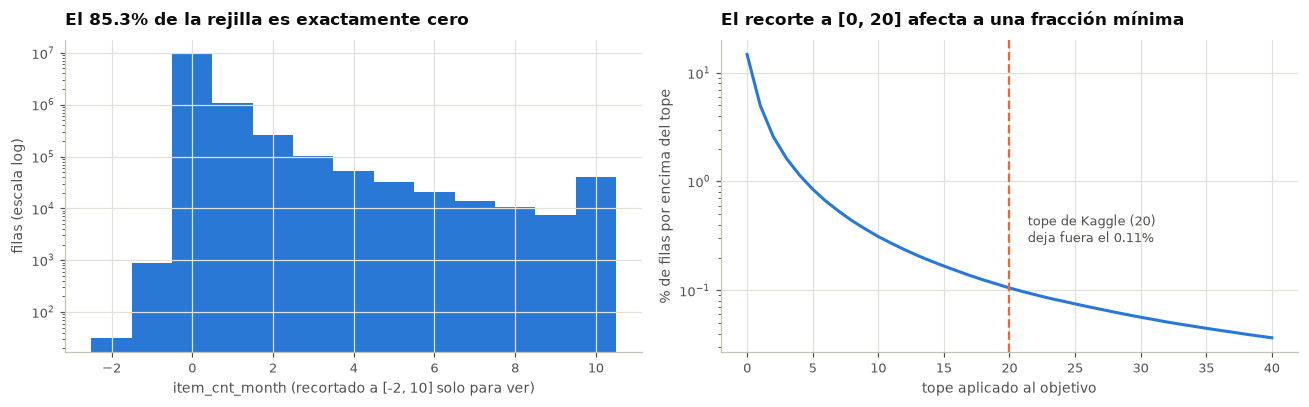

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))

# Panel izquierdo: la distribucion cruda. Se recorta a [-2, 10] solo para poder
# ver algo; la escala vertical es logaritmica porque el cero aplasta todo.
a1.hist(y.clip(-2, 10), bins=np.arange(-2.5, 11.5), color=AZUL)
a1.set_yscale("log")
a1.set_xlabel("item_cnt_month (recortado a [-2, 10] solo para ver)")
a1.set_ylabel("filas (escala log)")
a1.set_title(f"El {(y == 0).mean():.1%} de la rejilla es exactamente cero")

# Panel derecho: que fraccion de las filas queda fuera de cada tope.
topes = np.arange(0, 41)
fuera = [(y > t).mean() * 100 for t in topes]
a2.plot(topes, fuera, color=AZUL)
a2.axvline(20, color=NARANJA, linestyle="--", linewidth=1.5)
a2.annotate(f"tope de Kaggle (20)\ndeja fuera el {(y > 20).mean():.2%}",
            (20, (y > 20).mean() * 100), textcoords="offset points",
            xytext=(12, 30), fontsize=8.5, color=TINTA2)
a2.set_xlabel("tope aplicado al objetivo")
a2.set_ylabel("% de filas por encima del tope")
a2.set_yscale("log")
a2.set_title("El recorte a [0, 20] afecta a una fracción mínima")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02-1_objetivo.png", dpi=150)
plt.show()

**El objetivo es casi todo ceros, con una cola larguísima.** Esto condiciona todo lo que sigue:
no es un problema de regresión "normal", es uno de **demanda intermitente**.

La regla oficial de la competencia recorta el objetivo real al rango **[0, 20]**. Como se ve en
el panel derecho, afecta a una fracción diminuta de las filas, y a cambio elimina la influencia
desproporcionada de unos pocos valores extremos sobre el RMSE. **Se adopta.**

<a id="2"></a>
## 2. Selección de los rezagos

### Qué es un rezago

Para predecir noviembre, el dato más útil es cuánto se vendió en octubre. Ese valor —la misma
serie, un mes antes— es el **rezago 1**. El rezago 12 es el mismo mes del año anterior.

### Lo que dijo el EDA

El análisis de autocorrelación del Proyecto #1 concluyó tres cosas sobre la serie total:

1. La **PACF se corta después del rezago 1** (0.638 y luego 0.099): el mes anterior es el mejor
   predictor individual.
2. La **ACF decae gradualmente hasta el rezago 3** (0.64, 0.47, 0.37), todos significativos.
3. El **rezago 12 llegó a +0.259** contra una banda de ±0.336: sugerente pero no significativo,
   y no puede serlo con solo dos ciclos anuales.

### Lo que falta comprobar

Esas conclusiones se midieron sobre series **agregadas**. La pregunta que importa es si valen
sobre el panel completo de 10.9 millones de filas, que es lo que el modelo va a ver.

In [7]:
# Se construyen las caracteristicas aplicando los operadores en orden.
# Cada uno anade columnas al conjunto; ninguno elimina filas.
panel = panel_mensual(sales)                       # historial por par tienda-producto
precios = (sales.groupby(["date_block_num", "item_id"], observed=True)["item_price"]
           .mean().rename("precio_medio").reset_index()
           .astype({"date_block_num": "int8", "item_id": "int16", "precio_medio": "float32"}))

X = rejilla[["date_block_num", "shop_id", "item_id"]].copy()
y = rejilla["item_cnt_month"].clip(0, 20)          # el objetivo, ya con el tope de Kaggle

t0 = time.time()
X = UnirCatalogos(items, shops, cats).fit(X).transform(X)       # + categoria y nombres
X = CaracteristicasCalendario().fit(X).transform(X)             # + mes, diciembre, findes
X = LagFeatures(panel=panel, lags=(1, 2, 3, 12),
                ventanas=(3, 6), precios=precios).fit(X).transform(X)   # + rezagos
X = Mapper({"ciudad": ("shop_name", extraer_ciudad),
            "tipo_cat": ("item_category_name", extraer_tipo_categoria)}).fit(X).transform(X)
print(f"caracteristicas construidas en {time.time() - t0:.0f} s")
print(f"forma: {X.shape}  |  memoria: {X.memory_usage(deep=True).sum() / 1e9:.2f} GB")
display(X.head(3))

caracteristicas construidas en 45 s
forma: (10913850, 21)  |  memoria: 0.64 GB


,date_block_num,shop_id,item_id,item_category_id,mes_anio,anio,es_diciembre,dias_del_mes,findes_del_mes,lag_1,lag_2,lag_3,lag_12,media_3,media_6,item_lag_1,shop_lag_1,precio_lag_1,meses_de_vida,ciudad,tipo_cat
0,0,59,22154,37,1,2013,0,31,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,30.0,11.0
1,0,59,2552,58,1,2013,0,31,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.0,13.0
2,0,59,2554,58,1,2013,0,31,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.0,13.0


In [8]:
# Correlacion de cada rezago con el objetivo, sobre el panel completo.
# Solo se usan las filas donde el rezago existe: promediar sobre nulos
# imputados mediria el imputador, no el rezago.
candidatos = ["lag_1", "lag_2", "lag_3", "lag_12", "media_3", "media_6",
              "item_lag_1", "shop_lag_1", "precio_lag_1", "meses_de_vida"]
filas = []
for col in candidatos:
    m = X[col].notna()
    filas.append({
        "variable": col,
        "r con el objetivo": np.corrcoef(X.loc[m, col], y[m])[0, 1],
        "% disponible": m.mean() * 100,
    })
corr = pd.DataFrame(filas).set_index("variable").sort_values(
    "r con el objetivo", key=abs, ascending=False)
display(corr)

,r con el objetivo,% disponible
variable,,
lag_1,0.361173,96.654022
media_3,0.350447,96.654022
media_6,0.331836,96.654022
lag_2,0.294410,93.211351
lag_3,0.261256,89.712201
lag_12,0.182705,58.871013
item_lag_1,0.104181,96.654022
shop_lag_1,0.073398,96.654022
precio_lag_1,0.048035,96.654022


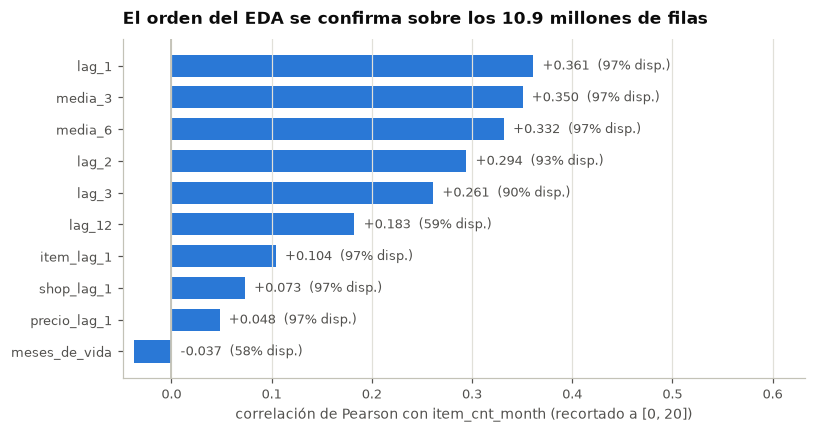

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
orden = corr.sort_values("r con el objetivo")
ax.barh(orden.index, orden["r con el objetivo"], color=AZUL, height=0.7)
ax.axvline(0, color=EJE, linewidth=1.2)
ax.set_xlabel("correlación de Pearson con item_cnt_month (recortado a [0, 20])")
ax.grid(axis="y", visible=False)
for i, (v, d) in enumerate(zip(orden["r con el objetivo"], orden["% disponible"])):
    # La etiqueta se ancla SIEMPRE a la derecha de la barra o del cero, lo que
    # este mas a la derecha. Si se anclara al extremo de una barra negativa, el
    # texto se iria hacia la izquierda y chocaria con el nombre de la variable.
    ax.annotate(f"{v:+.3f}  ({d:.0f}% disp.)", (max(v, 0), i), xytext=(6, 0),
                textcoords="offset points", va="center", ha="left",
                fontsize=8.5, color=TINTA2)
ax.set_xlim(min(orden["r con el objetivo"].min() * 1.3, -0.02),
            orden["r con el objetivo"].max() * 1.75)
ax.set_title("El orden del EDA se confirma sobre los 10.9 millones de filas")
fig.savefig(FIGURES_DIR / "02-2_correlacion_rezagos.png", dpi=150)
plt.show()

### Decisión sobre los rezagos

**El orden se confirma**: `lag_1` (+0.361) > `lag_2` (+0.294) > `lag_3` (+0.261) > `lag_12`
(+0.183). Es exactamente la jerarquía que predijo la ACF del EDA, ahora medida sobre el panel
completo en lugar de sobre series agregadas.

| Variable | Decisión | Criterio |
|---|---|---|
| `lag_1`, `lag_2`, `lag_3` | **Se incluyen** | Los tres rezagos significativos de la ACF; la correlación lo confirma |
| `lag_12` | **Se incluye** | Más débil (+0.183) y disponible solo en el 59 % de las filas, pero es el único que captura diciembre. El EDA dejó claro que la estacionalidad existe aunque la ACF no pueda probarla con 34 observaciones |
| `media_3`, `media_6` | **Se incluyen** | Suavizan el ruido de un mes suelto. En demanda intermitente, "cuánto vende normalmente" es más estable que "cuánto vendió justo el mes pasado" |
| `item_lag_1`, `shop_lag_1` | **Se incluyen** | Correlación baja por sí solas (+0.104 y +0.073), pero son **lo único disponible** para el 48 % de pares sin historial |
| `precio_lag_1` | **Se incluye** | El EDA mostró que la mezcla de producto cambia: se vende menos cantidad de cosas más caras |
| `meses_de_vida` | **Se incluye** | Un producto nuevo y uno veterano con la misma venta el mes pasado no se comportan igual |
| Rezagos 4 a 11 | **Se descartan** | La ACF ya no es significativa ahí y cada uno añade 44 MB y un cruce de tablas. El coste no se justifica |

<a id="3"></a>
## 3. Los seis procesos de ingeniería de características

El enunciado pide aplicar **al menos una operación de cada proceso**, indicando el criterio de
selección. Se recorren uno por uno.

### 3.i Imputación de variables numéricas

**No hay que forzar nada**: los valores ausentes aparecen solos, y por una razón legítima.

In [10]:
nulos = pd.DataFrame({
    "nulos": X.isna().sum(),
    "% nulos": (X.isna().mean() * 100).round(2),
})
display(nulos[nulos["nulos"] > 0].sort_values("% nulos", ascending=False))

,nulos,% nulos
meses_de_vida,4625508,42.38
lag_12,4488756,41.13
lag_3,1122795,10.29
lag_2,740903,6.79
lag_1,365175,3.35
media_3,365175,3.35
media_6,365175,3.35
item_lag_1,365175,3.35
shop_lag_1,365175,3.35
precio_lag_1,365175,3.35


**De dónde salen estos nulos.** El rezago 12 de un mes anterior al número 12 no existe: no hay
forma de saber cuánto vendió un par doce meses antes de que empezaran los datos. Lo mismo con
`meses_de_vida` para los pares que nunca vendieron nada.

Es importante distinguir dos situaciones que el operador `LagFeatures` ya separa:

| Situación | Valor | Por qué |
|---|---|---|
| El mes anterior existe y el par no vendió | **0** | Es información real: no vendió |
| El mes anterior no existe en los datos | **nulo** | No es que vendiera cero: es que no se sabe |

Confundirlas le enseñaría al modelo algo falso.

**Operación elegida:** `SimpleImputer(strategy="constant", fill_value=0, add_indicator=True)`
para la familia de rezagos, y `SimpleImputer(strategy="median")` para `precio_lag_1`.

**Criterio:** para los rezagos, cero es el valor semánticamente correcto —un par sin historial
es un par que no ha vendido—, y el indicador que añade `add_indicator` le da al modelo una
bandera que dice "este cero es un *no sé*, no un *no vendió*". Para el precio, cero sería
absurdo (ningún producto es gratis), así que se usa la mediana.

In [11]:
# Demostracion sobre la columna mas afectada.
from sklearn.impute import SimpleImputer

muestra = X[["lag_12"]].head(200_000)
imputador = SimpleImputer(strategy="constant", fill_value=0, add_indicator=True)
resultado = imputador.fit_transform(muestra)
print(f"antes : {muestra['lag_12'].isna().sum():,} nulos de {len(muestra):,}")
print(f"despues: {np.isnan(resultado[:, 0]).sum():,} nulos")
print(f"columnas de salida: {resultado.shape[1]}  "
      f"(la segunda es la bandera 'este valor estaba ausente')")

antes : 200,000 nulos de 200,000
despues: 0 nulos
columnas de salida: 1  (la segunda es la bandera 'este valor estaba ausente')


C:\Users\dgarc\anaconda3\envs\env_predict_future_sales\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['lag_12']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(


### 3.ii Imputación de variables categóricas

Aquí **sí** hay que forzar la situación, y el enunciado lo autoriza expresamente: *"Si el dataset
está completo (...) se deberá forzar que sea posible aplicarlos (por ejemplo, eliminando algunos
datos de forma aleatoria)"*.

El EDA verificó que las seis tablas tienen **cero nulos**. No hay ninguna variable categórica
incompleta que imputar.

In [12]:
# Se borra al azar el 1 % de la ciudad, con semilla fija para que el resultado
# sea identico en cada ejecucion. Esto NO es una tecnica de modelado: es la
# forma de poder demostrar la imputacion categorica que pide el enunciado.
from sklearn.impute import SimpleImputer

rng = np.random.default_rng(42)
demo = X[["ciudad"]].head(500_000).copy()
mascara = rng.random(len(demo)) < 0.01
demo.loc[mascara, "ciudad"] = np.nan
print(f"huecos creados a proposito: {demo['ciudad'].isna().sum():,} "
      f"({demo['ciudad'].isna().mean():.2%})")

imp_cat = SimpleImputer(strategy="most_frequent")
relleno = imp_cat.fit_transform(demo)
print(f"nulos tras imputar       : {np.isnan(relleno).sum():,}")
print(f"valor usado para rellenar: ciudad {imp_cat.statistics_[0]:.0f} "
      f"(la mas frecuente del entrenamiento)")

huecos creados a proposito: 5,050 (1.01%)
nulos tras imputar       : 0
valor usado para rellenar: ciudad 13 (la mas frecuente del entrenamiento)


**Operación elegida:** `SimpleImputer(strategy="most_frequent")`.

**Criterio:** la moda es la única estrategia con sentido para una variable categórica —no existe
"la media de una ciudad"— y preserva la distribución mejor que inventar una categoría nueva,
dado que el porcentaje afectado es mínimo.

**Y hay un segundo origen de nulos, este sí real.** El operador `Mapper` asigna `nulo` a
cualquier ciudad o tipo de categoría que no estuviera en el entrenamiento, en vez de inventarle
un código. Si en producción apareciera una tienda en una ciudad nueva, este imputador es lo que
evita que el pipeline falle.

### 3.iii Codificación de variables categóricas

El modelo no sabe leer `"Москва ТЦ \"Семеновский\""`. Hay que convertir el texto en números, y
antes de codificar hay que **extraer**: la ciudad está dentro del nombre de la tienda y la
plataforma dentro del nombre de la categoría.

In [13]:
# Ejemplos de la extraccion, antes de codificar.
ejemplos = pd.DataFrame({
    "shop_name": shops.shop_name.head(6),
    "ciudad extraida": shops.shop_name.head(6).map(extraer_ciudad),
})
display(ejemplos)
ejemplos2 = pd.DataFrame({
    "item_category_name": cats.item_category_name.head(6),
    "tipo extraido": cats.item_category_name.head(6).map(extraer_tipo_categoria),
})
display(ejemplos2)
print(f"\n60 tiendas -> {shops.shop_name.map(extraer_ciudad).nunique()} ciudades")
print(f"84 categorias -> {cats.item_category_name.map(extraer_tipo_categoria).nunique()} tipos")

,shop_name,ciudad extraida
0,"!Якутск Орджоникидзе, 56 фран",Якутск
1,"!Якутск ТЦ ""Центральный"" фран",Якутск
2,"Адыгея ТЦ ""Мега""",Адыгея
3,"Балашиха ТРК ""Октябрь-Киномир""",Балашиха
4,"Волжский ТЦ ""Волга Молл""",Волжский
5,"Вологда ТРЦ ""Мармелад""",Вологда


,item_category_name,tipo extraido
0,PC - Гарнитуры/Наушники,PC
1,Аксессуары - PS2,Аксессуары
2,Аксессуары - PS3,Аксессуары
3,Аксессуары - PS4,Аксессуары
4,Аксессуары - PSP,Аксессуары
5,Аксессуары - PSVita,Аксессуары



60 tiendas -> 31 ciudades
84 categorias -> 20 tipos


**Operación elegida:** el operador propio `Mapper` (extrae y codifica con un diccionario
aprendido en `fit`), más `OrdinalEncoder` para el bloque categórico del pipeline.

**Criterio de selección — por qué no `OneHotEncoder`.** Es la decisión más importante de esta
sección y es puramente aritmética:

| Variable | Valores distintos | Columnas que crearía *one-hot* | Memoria sobre 10.9 M filas |
|---|---|---|---|
| `item_id` | 21 807 | 21 807 | **950 GB** |
| `shop_id` | 60 | 60 | 2.6 GB |
| `tipo_cat` | 20 | 20 | 0.9 GB |

*One-hot* sobre `item_id` es sencillamente imposible: la máquina tiene 8 GB. Se usa codificación
**ordinal**, que ocupa una sola columna por variable. El inconveniente conocido de la ordinal
—que introduce un orden falso, como si el producto 500 fuera "mayor" que el 200— **no afecta a
los modelos de árbol**, que son los que mejor rinden en este problema: un árbol solo pregunta
"¿es el código menor que X?" y puede aislar cualquier grupo con cortes sucesivos.

Las agrupaciones del `Mapper` (31 ciudades, 20 tipos) son precisamente la forma de dar
información categórica **de baja cardinalidad** que sí sirve a los modelos lineales.

### 3.iv Tratamiento de outliers

El EDA documentó extremos reales: una transacción de **2 169 unidades** y un precio de
**307 980 rublos**. También documentó que **tres de los cuatro extremos se explican leyendo el
nombre del producto** —un servicio de entrega, un lote de bolsas, una licencia corporativa de
522 puestos— y que recortarlos borraría información legítima.

Aquí hay una tensión real con el enunciado, que exige aplicar tratamiento de outliers. Se
resuelve distinguiendo **dónde** hay un error y **dónde** hay un valor extremo pero correcto.

In [14]:
# El objetivo: el recorte lo impone la competencia, no es una decision nuestra.
print("OBJETIVO (item_cnt_month)")
print(f"  antes  : min {rejilla.item_cnt_month.min():,.0f} / max {rejilla.item_cnt_month.max():,.0f}")
print(f"  despues: min {y.min():,.0f} / max {y.max():,.0f}   (recorte oficial a [0, 20])")
print(f"  filas afectadas: {(rejilla.item_cnt_month != y).sum():,} "
      f"({(rejilla.item_cnt_month != y).mean():.3%})")

OBJETIVO (item_cnt_month)


  antes  : min -22 / max 2,253


  despues: min 0 / max 20   (recorte oficial a [0, 20])


  filas afectadas: 12,378 (0.113%)


In [15]:
# El precio: aqui si hay errores de captura, y el capper se encarga.
capper = OutlierCapper(inferior=0.01, superior=0.99)
precio_antes = X[["precio_lag_1"]].dropna()
precio_despues = capper.fit(precio_antes).transform(precio_antes)

print("PRECIO (precio_lag_1)")
print(f"  antes  : min {precio_antes.precio_lag_1.min():,.1f} / "
      f"max {precio_antes.precio_lag_1.max():,.1f}")
print(f"  despues: min {precio_despues.precio_lag_1.min():,.1f} / "
      f"max {precio_despues.precio_lag_1.max():,.1f}")
print(f"  limites aprendidos: {capper.limites_['precio_lag_1'][0]:,.1f} a "
      f"{capper.limites_['precio_lag_1'][1]:,.1f}")

PRECIO (precio_lag_1)
  antes  : min 0.0 / max 36,990.0
  despues: min 0.0 / max 4,290.0
  limites aprendidos: 0.0 a 4,290.0


**Operaciones elegidas:** recorte del objetivo a **[0, 20]** y `OutlierCapper` en los percentiles
**1 y 99** sobre el precio.

**Criterio:**

- **En el objetivo**, el recorte **no es una decisión de modelado**: es la regla publicada de la
  competencia, que evalúa contra valores reales ya recortados a ese rango. No aplicarlo sería
  optimizar una métrica distinta de la que se puntúa. Afecta a 12 378 filas: el **0.11 %**.
- **En el precio**, sí hay errores de captura reales —el EDA encontró un precio de −1— y un
  recorte por percentiles los neutraliza sin eliminar filas.
- **En ningún otro sitio.** No se aplica *winsorizing* a los rezagos ni a los agregados: ahí las
  colas son la señal, y el EDA fue explícito al respecto.

### 3.v Transformación de variables numéricas

El EDA midió que `item_price` va de 5 rublos a 307 980, con mediana 399: tres órdenes de
magnitud y un sesgo enorme. Un modelo lineal no puede trabajar bien con eso.

sesgo antes  : +3.48
sesgo despues: -0.07


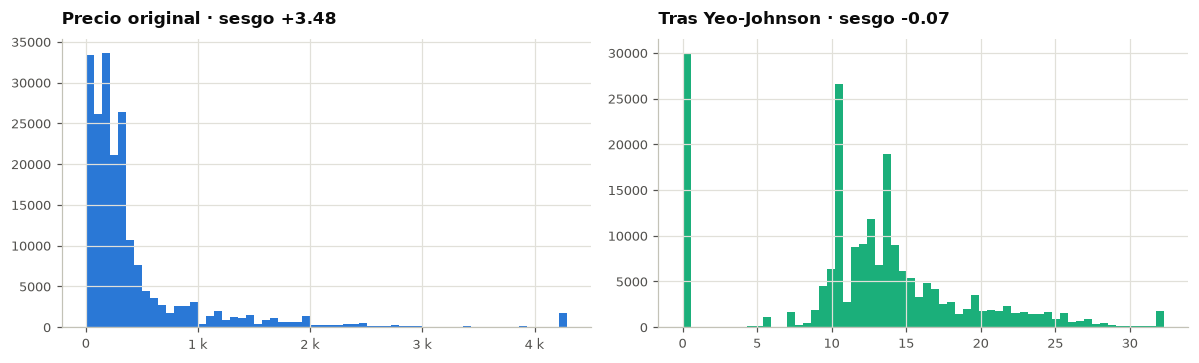

In [16]:
from sklearn.preprocessing import PowerTransformer

muestra_precio = precio_despues.head(200_000)
pt = PowerTransformer(method="yeo-johnson", standardize=False)
transformado = pt.fit_transform(muestra_precio)

print(f"sesgo antes  : {muestra_precio.precio_lag_1.skew():+.2f}")
print(f"sesgo despues: {pd.Series(transformado.ravel()).skew():+.2f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.4))
a1.hist(muestra_precio.precio_lag_1, bins=60, color=AZUL)
a1.set_title(f"Precio original · sesgo {muestra_precio.precio_lag_1.skew():+.2f}")
a1.xaxis.set_major_formatter(FMT)
a2.hist(transformado.ravel(), bins=60, color=AQUA)
a2.set_title(f"Tras Yeo-Johnson · sesgo {pd.Series(transformado.ravel()).skew():+.2f}")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02-3_transformacion.png", dpi=150)
plt.show()

**Operación elegida:** `PowerTransformer(method="yeo-johnson")` sobre el precio.

**Criterio — por qué Yeo-Johnson y no el logaritmo.** El logaritmo es la opción habitual para
corregir sesgo, pero **no está definido en cero ni en los negativos**, y aquí ambos existen: el
EDA encontró un precio negativo y, tras los rezagos, hay columnas con ceros legítimos.
Yeo-Johnson es la generalización que sí los admite, y además **estima su parámetro de los
datos** en lugar de imponer una forma fija.

**El objetivo no se transforma.** Tiene ceros en el 85 % de las filas y valores negativos
(devoluciones netas). Además, la métrica de la competencia es el RMSE **en unidades reales**:
transformar el objetivo optimizaría una métrica distinta.

### 3.vi Escalado de características

Las variables llegan en escalas incomparables: `item_id` va hasta 22 170, `es_diciembre` vale 0
o 1 y `precio_lag_1` llega a miles.

In [17]:
from sklearn.preprocessing import StandardScaler

numericas = ["lag_1", "lag_2", "lag_3", "lag_12", "media_3", "media_6",
             "item_lag_1", "shop_lag_1", "meses_de_vida"]
muestra_num = X[numericas].head(200_000).fillna(0)

escalador = StandardScaler()
escalado = escalador.fit_transform(muestra_num)

antes_despues = pd.DataFrame({
    "media antes": muestra_num.mean(), "desv antes": muestra_num.std(),
    "media despues": escalado.mean(axis=0), "desv despues": escalado.std(axis=0),
}).round(3)
display(antes_despues)

,media antes,desv antes,media despues,desv despues
lag_1,0.000,0.00,0.0,0.0
lag_2,0.000,0.00,0.0,0.0
lag_3,0.000,0.00,0.0,0.0
lag_12,0.000,0.00,0.0,0.0
media_3,0.000,0.00,0.0,0.0
media_6,0.000,0.00,0.0,0.0
item_lag_1,0.000,0.00,0.0,0.0
shop_lag_1,0.000,0.00,0.0,0.0
meses_de_vida,-1.382,3.68,-0.0,1.0


**Operación elegida:** `StandardScaler` (resta la media y divide por la desviación típica).

**Criterio:** los modelos lineales regularizados —Ridge, Lasso— penalizan el tamaño de los
coeficientes, así que **sin escalar penalizarían más a las variables que vienen en unidades
pequeñas**, lo cual no tiene nada que ver con su utilidad. Las redes neuronales no convergen bien
sin escalar. Los modelos de árbol no lo necesitan, pero tampoco les perjudica: un árbol parte por
umbrales y es indiferente a un cambio de escala. Como el torneo del notebook 04 enfrenta familias
de los tres tipos, se escala para todas y así la comparación es limpia.

<a id="4"></a>
## 4. La lista escrita del proceso

Esto es lo que el notebook 03 tendrá que construir, en este orden.

### 4.1 Variables de entrada del pipeline

El pipeline recibe únicamente **tres columnas**: `shop_id`, `item_id` y `date_block_num`. Todo lo
demás lo genera él. Esto es deliberado: `test.csv` solo trae `ID`, `shop_id` e `item_id`, y el
mes a predecir es la constante 34. Así el notebook 05 puede ir del archivo crudo a las
predicciones sin un solo paso intermedio.

### 4.2 Pasos de generación de variables

| # | Operador | Qué añade |
|---|---|---|
| 1 | `UnirCatalogos` | `item_category_id`, `shop_name`, `item_category_name` |
| 2 | `CaracteristicasCalendario` | `mes_anio`, `anio`, `es_diciembre`, `dias_del_mes`, `findes_del_mes` |
| 3 | `LagFeatures` | `lag_1`, `lag_2`, `lag_3`, `lag_12`, `media_3`, `media_6`, `item_lag_1`, `shop_lag_1`, `precio_lag_1`, `meses_de_vida` |
| 4 | `Mapper` | `ciudad`, `tipo_cat` (y retira las columnas de texto) |

### 4.3 Qué transformación recibe cada variable

| Bloque | Variables | Imputación | Outliers | Transformación | Escalado |
|---|---|---|---|---|---|
| **Rezagos** | `lag_1`, `lag_2`, `lag_3`, `lag_12`, `media_3`, `media_6`, `item_lag_1`, `shop_lag_1`, `meses_de_vida` | constante 0 + indicador | — | — | `StandardScaler` |
| **Precio** | `precio_lag_1` | mediana | `OutlierCapper` p1–p99 | Yeo-Johnson | `StandardScaler` |
| **Calendario** | `mes_anio`, `anio`, `es_diciembre`, `dias_del_mes`, `findes_del_mes` | — | — | — | `StandardScaler` |
| **Categóricas / exógenas** | `shop_id`, `item_id`, `item_category_id`, `ciudad`, `tipo_cat` | moda | — | — | `OrdinalEncoder` |

### 4.4 Mecanismos de mapeo

| Mapeo | Origen | Destino | Cómo |
|---|---|---|---|
| Ciudad | `shop_name` | `ciudad` (31 códigos) | Primera palabra del nombre, sin el `!` inicial que el EDA identificó como marca de tienda duplicada |
| Tipo de categoría | `item_category_name` | `tipo_cat` (20 códigos) | Texto anterior al guion: `"Игры - PS3"` → `"Игры"` |
| Producto → categoría | `item_id` | `item_category_id` | Cruce con `items.csv` |
| Valor no visto | cualquiera | `nulo` | Se marca como ausente en vez de inventar un código |

### 4.5 El objetivo

`item_cnt_month`, obtenido sumando `item_cnt_day` por mes, **recortado a [0, 20]** por la regla
de la competencia. No se transforma.

<a id="5"></a>
## 5. Fuga de información: la regla que no se puede romper

El enunciado lo marca en negrita, y con razón: *"cada lag debe construirse únicamente con meses
anteriores al mes que se predice"*.

**Por qué importa tanto.** Si un rezago se calcula con información del propio mes o de meses
posteriores, el modelo entrena con la respuesta puesta. El síntoma es un resultado excelente en
validación y un fracaso en Kaggle, sin ninguna señal de alarma por el camino.

**Cómo se evita aquí.** El operador `LagFeatures` no desplaza ni ordena nada: hace un **cruce de
tablas por clave**. Para la fila del mes *m*, el rezago *k* se busca con la clave
`(tienda, producto, m − k)`. Por construcción, es imposible que toque el mes *m* o uno posterior.

**Cómo se verifica.** No se da por supuesto: hay una prueba automatizada.

In [18]:
# La prueba usa un dataset de juguete donde la respuesta se conoce de memoria:
# una sola tienda y un solo producto vendiendo 10, 20, 30 y 40 unidades en
# meses consecutivos. El rezago 1 del mes 2 TIENE que ser 20, no 30.
import subprocess
import sys

from predict_future_sales.config import PROJ_ROOT

salida = subprocess.run(
    [sys.executable, "-m", "pytest", str(PROJ_ROOT / "tests"), "-q"],
    capture_output=True, text=True, cwd=str(PROJ_ROOT),
)
print(salida.stdout[-900:])

.........                                                                [100%]
9 passed in 4.97s



In [19]:
# Verificacion adicional sobre los datos reales: ningun rezago puede coincidir
# sistematicamente con el valor del propio mes. Si lo hiciera, estaria copiando
# la respuesta.
muestra = X.head(2_000_000)
objetivo = y.head(2_000_000)
coincidencias = (muestra["lag_1"] == objetivo).mean()
print(f"filas donde lag_1 coincide con el objetivo: {coincidencias:.1%}")
print("  (es normal que sea alto: ambos valen cero en una rejilla vacia al 85 %)")
solo_no_cero = (objetivo > 0)
print(f"filas con venta > 0 donde lag_1 coincide  : "
      f"{(muestra.loc[solo_no_cero, 'lag_1'] == objetivo[solo_no_cero]).mean():.1%}")
print("  (si esto fuera ~100 %, el rezago se estaria copiando a si mismo)")

filas donde lag_1 coincide con el objetivo: 64.2%
  (es normal que sea alto: ambos valen cero en una rejilla vacia al 85 %)
filas con venta > 0 donde lag_1 coincide  : 13.4%
  (si esto fuera ~100 %, el rezago se estaria copiando a si mismo)


### Y una segunda fuente de fuga, más sutil

Los agregados `item_lag_1` y `shop_lag_1` son medias calculadas sobre otras filas. Si se
calcularan con el mes en curso, cada fila contendría un promedio que la incluye a ella misma: una
forma encubierta de ver la respuesta.

Por eso se calculan **siempre sobre el mes anterior** y pasan por el mismo mecanismo de cruce
desplazado que los rezagos. El mismo código, la misma garantía.

---

## Resumen

| Lo que se decidió | Valor |
|---|---|
| Conjunto de trabajo | Rejilla mensual, 10 913 850 filas, 85 % ceros |
| Objetivo | `item_cnt_month` recortado a [0, 20], sin transformar |
| Rezagos | 1, 2, 3, 12 + medias móviles de 3 y 6 |
| Variables totales | 21 |
| Imputación | Constante 0 + indicador (rezagos); mediana (precio); moda (categóricas) |
| Outliers | Recorte oficial [0, 20] del objetivo; percentiles 1–99 del precio |
| Transformación | Yeo-Johnson en el precio |
| Escalado | `StandardScaler` |
| Codificación | `Mapper` propio + `OrdinalEncoder` |

**Siguiente paso:** el notebook `03_feature_creation.ipynb` convierte esta lista en un objeto
`Pipeline` de scikit-learn y lo guarda en un `.pkl`.